# C23 — Laboratório de Inteligência Artificial
## Aula 04 — Classificação

**Objetivo da aula:** compreender como um modelo de classificação transforma atributos de entrada em classes e aplicar um classificador de regressão logística a um problema real.


### 1. Classificação

Classificação é uma tarefa de **aprendizado supervisionado** na qual conhecemos os atributos de entrada e os rótulos das amostras utilizadas no treinamento.

O objetivo é aprender uma função que associe cada amostra a uma das classes possíveis.

Na regressão, a saída é um valor numérico contínuo.

Na classificação, a saída pertence a um conjunto **discreto de classes**.

Exemplos:

- detectar se um e-mail é **spam ou legítimo**;
- classificar uma imagem como **gato, cachorro ou outro animal**;
- identificar se um exame indica **presença ou ausência** de determinada condição;
- classificar uma notícia por **categoria**.

O modelo aprende padrões presentes nos dados de treinamento para conseguir classificar novas amostras.


### 2. Tipos de classificação

A classificação pode ser organizada de acordo com a quantidade de classes possíveis e com a quantidade de classes que uma amostra pode receber.

#### Classificação binária

Existem duas classes possíveis.

Exemplo:

- `0` — não sobreviveu;
- `1` — sobreviveu.

#### Classificação multiclasses

Existem três ou mais classes possíveis, e cada amostra pertence a apenas uma delas.

Exemplo:

- `0` — baixa;
- `1` — média;
- `2` — alta.

#### Classificação multilabel

Uma mesma amostra pode pertencer a várias classes simultaneamente.

Exemplo: uma imagem pode conter simultaneamente as classes **pessoa**, **carro** e **cachorro**.

Nesta aula, trabalharemos com **classificação binária**.


### 3. Fronteira de decisão

Um classificador precisa separar as classes no espaço formado pelos atributos.

Imagine duas variáveis de entrada, `x₁` e `x₂`. Cada amostra pode ser representada como um ponto nesse espaço.

O modelo procura uma **fronteira de decisão** que divida o espaço em regiões associadas às diferentes classes.

A fronteira pode ser:

- linear, como uma reta ou um plano;
- não linear, dependendo do modelo e da transformação utilizada.

A ideia central é:

> **Aprender uma regra que permita separar as classes e generalizar essa separação para novas amostras.**

Quanto mais distante uma amostra estiver da fronteira, maior tende a ser a confiança do modelo em sua classificação.
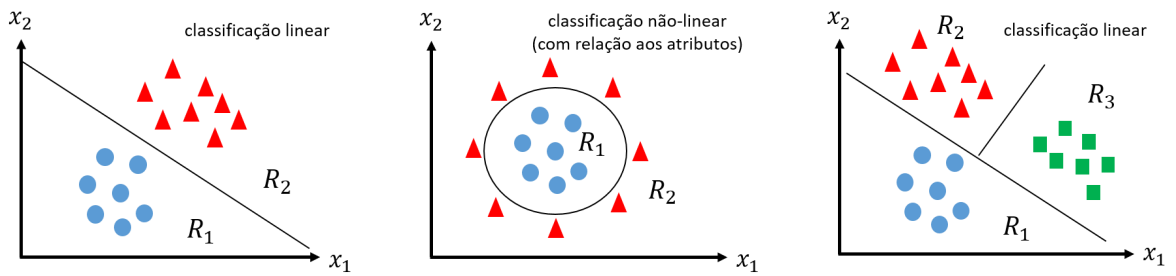

### 4. Regressão logística

Primeiro, o modelo calcula uma função discriminante:

$$
g(x) = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n
$$

Essa função pode assumir qualquer valor real.

Em seguida, esse resultado passa pela **função logística ou sigmoide**:

$$
f(g(x)) = \frac{1}{1 + e^{-g(x)}}
$$

A sigmoide transforma qualquer valor de entrada em um valor entre **0 e 1**.

Esse valor pode ser interpretado como a probabilidade estimada de uma amostra pertencer à classe positiva.

A regressão logística, portanto, produz inicialmente uma **probabilidade**, e não diretamente a classe.


### 5. Probabilidade e limiar de decisão

Suponha que o modelo produza:

$$
P(y=1|x)=0,82
$$

Isso significa que o modelo estima uma probabilidade de **82%** para a classe positiva.

Para transformar essa probabilidade em uma classe, precisamos definir um **limiar de decisão**.

O valor mais comum é:

$$
limiar = 0,5
$$

Assim:

- se `P(y=1|x) < 0,5` → classe `0`;
- se `P(y=1|x) ≥ 0,5` → classe `1`.

O limiar não precisa ser obrigatoriamente 0,5.

Em uma aplicação real, podemos alterá-lo quando os erros de uma classe forem mais importantes que os erros da outra.

Por exemplo, em um sistema de detecção de uma condição crítica, pode ser preferível reduzir o número de casos positivos que o modelo deixa passar, mesmo que isso aumente a quantidade de falsos positivos.

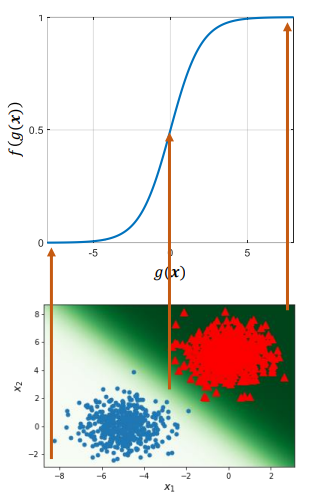


### 6. Avaliação de classificadores

Apenas observar a porcentagem de acertos pode ser insuficiente.

Considere um problema em que 95% das amostras pertencem à classe `0`. Um modelo que sempre respondesse `0` teria 95% de acurácia, mas seria incapaz de identificar a classe `1`.

Por isso, analisaremos:

- **Acurácia:** proporção total de classificações corretas.
- **Precisão (Precision):** entre as amostras classificadas como positivas, quantas realmente são positivas?
- **Revocação (Recall):** entre as amostras realmente positivas, quantas foram identificadas pelo modelo?
- **F1-score:** média harmônica entre precisão e revocação.
- **Matriz de confusão:** mostra separadamente acertos e erros de cada classe.

A escolha da métrica deve considerar o custo dos diferentes tipos de erro.


### 7. Matriz de confusão

Em uma classificação binária, temos quatro possibilidades:

| | Real: 0 | Real: 1 |
|---|---:|---:|
| **Predito: 0** | Verdadeiro Negativo (TN) | Falso Negativo (FN) |
| **Predito: 1** | Falso Positivo (FP) | Verdadeiro Positivo (TP) |

- **Verdadeiro Positivo:** o modelo previu 1 e a amostra realmente era 1.
- **Verdadeiro Negativo:** o modelo previu 0 e a amostra realmente era 0.
- **Falso Positivo:** o modelo previu 1, mas a amostra era 0.
- **Falso Negativo:** o modelo previu 0, mas a amostra era 1.

Esses quatro valores permitem entender **como** o modelo está errando, e não apenas quanto está acertando.


# 2. Prática Guiada

Vamos construir um classificador de regressão logística para prever a sobrevivência de passageiros do Titanic.

Execute as células na ordem e observe os resultados produzidos pelo modelo.

Durante a prática, procure relacionar cada etapa do código aos conceitos apresentados na seção anterior.


In [1]:
# Importamos as bibliotecas necessárias para a prática.
# Pandas e NumPy serão utilizados para manipulação dos dados.
# Matplotlib e Seaborn serão utilizados para visualização.
# O scikit-learn fornece as ferramentas de pré-processamento,
# divisão dos dados, classificação e avaliação do modelo.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [2]:
# Carregamos o conjunto de dados Titanic.
# Utilizamos as mesmas informações trabalhadas nas aulas anteriores
# para manter a continuidade do problema.

try:
    df = sns.load_dataset("titanic")
except Exception:
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
    df = pd.read_csv(url)

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Selecionamos apenas atributos que podem estar disponíveis
# antes de conhecermos o resultado do passageiro.
#
# A variável "survived" será o nosso alvo:
# 0 = não sobreviveu
# 1 = sobreviveu
#
# Não utilizamos "alive", pois ela representa exatamente o mesmo
# resultado que queremos prever e causaria vazamento de informação.

features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features].copy()
y = df["survived"].copy()

print(f"Amostras: {X.shape[0]}")
print(f"Atributos utilizados: {X.shape[1]}")
print("\nAtributos:")
print(X.columns.tolist())


Amostras: 891
Atributos utilizados: 7

Atributos:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']


In [4]:
# Dividimos os dados em treinamento e teste.
#
# O modelo aprenderá apenas com X_train e y_train.
# O conjunto de teste será utilizado somente para avaliar
# o comportamento do modelo em dados não utilizados no treinamento.
#
# stratify=y mantém aproximadamente a mesma proporção das classes
# nos conjuntos de treinamento e teste.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Amostras de treinamento: {X_train.shape[0]}")
print(f"Amostras de teste: {X_test.shape[0]}")

print("\nDistribuição das classes no treinamento:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nDistribuição das classes no teste:")
print(y_test.value_counts(normalize=True).sort_index())


Amostras de treinamento: 712
Amostras de teste: 179

Distribuição das classes no treinamento:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Distribuição das classes no teste:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [5]:
# Separamos os atributos numéricos e categóricos.
# Os numéricos terão valores ausentes preenchidos pela mediana
# e depois serão padronizados.
#
# Os categóricos terão valores ausentes preenchidos pela categoria
# mais frequente e depois serão transformados por One-Hot Encoding.

atributos_numericos = ["pclass", "age", "sibsp", "parch", "fare"]
atributos_categoricos = ["sex", "embarked"]

preprocessamento = ColumnTransformer(
    transformers=[
        (
            "numericos",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="median")),
                ("escalonamento", StandardScaler())
            ]),
            atributos_numericos
        ),
        (
            "categoricos",
            Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("codificacao", OneHotEncoder(handle_unknown="ignore"))
            ]),
            atributos_categoricos
        )
    ]
)

preprocessamento


ColumnTransformer(transformers=[('numericos',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonamento',
                                                  StandardScaler())]),
                                 ['pclass', 'age', 'sibsp', 'parch', 'fare']),
                                ('categoricos',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('codificacao',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'embarked'])])

In [6]:
# Criamos o pipeline completo.
#
# Primeiro, os dados passam pelo pré-processamento.
# Depois, são enviados para a regressão logística.
#
# O parâmetro C controla a força da regularização.
# Aqui utilizamos o valor padrão 1.0.

modelo = Pipeline([
    ("preprocessamento", preprocessamento),
    ("classificador", LogisticRegression(C=1.0, max_iter=1000))
])

# O modelo é ajustado somente com os dados de treinamento.
modelo.fit(X_train, y_train)

print("Modelo treinado.")


Modelo treinado.


In [7]:
# O classificador possui coeficientes associados aos atributos
# transformados pelo pré-processamento.
#
# O sinal do coeficiente indica a direção da contribuição para
# a classe positiva, enquanto a magnitude indica a intensidade
# da contribuição na escala utilizada pelo modelo.

nomes_atributos = modelo.named_steps["preprocessamento"].get_feature_names_out()
coeficientes = modelo.named_steps["classificador"].coef_[0]

coeficientes_df = pd.DataFrame({
    "atributo": nomes_atributos,
    "coeficiente": coeficientes
})

coeficientes_df["magnitude"] = coeficientes_df["coeficiente"].abs()

coeficientes_df.sort_values(
    "magnitude",
    ascending=False
).reset_index(drop=True)


,atributo,coeficiente,magnitude
0,categoricos__sex_male,-1.320718,1.320718
1,categoricos__sex_female,1.299444,1.299444
2,numericos__pclass,-0.921972,0.921972
3,numericos__age,-0.502815,0.502815
4,categoricos__embarked_S,-0.358305,0.358305
5,categoricos__embarked_Q,0.304784,0.304784
6,numericos__sibsp,-0.260607,0.260607
7,numericos__fare,0.100269,0.100269
8,numericos__parch,-0.066424,0.066424
9,categoricos__embarked_C,0.032247,0.032247


In [8]:
# Fazemos as previsões de probabilidade para o conjunto de teste.
#
# predict_proba retorna duas probabilidades para cada amostra:
# coluna 0 → probabilidade da classe 0
# coluna 1 → probabilidade da classe 1
#
# Nesta etapa ainda não estamos escolhendo a classe final.

probabilidades = modelo.predict_proba(X_test)

probabilidade_classe_1 = probabilidades[:, 1]

resultado = pd.DataFrame({
    "real": y_test.to_numpy(),
    "probabilidade_classe_1": probabilidade_classe_1
}, index=y_test.index)

resultado.head(10)


,real,probabilidade_classe_1
565,0,0.067973
160,0,0.047641
553,1,0.155243
860,0,0.035711
241,1,0.672378
559,1,0.442780
387,1,0.752804
536,0,0.327596
698,0,0.347025
99,0,0.161380


In [9]:
# Utilizamos o limiar padrão de 0.5 para transformar probabilidade em classe.
#
# Se a probabilidade de pertencer à classe 1 for maior ou igual a 0.5,
# classificamos a amostra como classe 1.
# Caso contrário, classificamos como classe 0.

limiar = 0.5

y_pred = (probabilidade_classe_1 >= limiar).astype(int)

print(f"Limiar utilizado: {limiar}")
print("\nPrimeiras previsões:")
print(y_pred[:10])


Limiar utilizado: 0.5

Primeiras previsões:
[0 0 0 0 1 0 1 0 0 0]


In [10]:
# Calculamos quatro métricas para avaliar o classificador.
#
# Acurácia → proporção total de acertos.
# Precisão → entre os positivos previstos, quantos eram realmente positivos.
# Recall → entre os positivos reais, quantos foram encontrados.
# F1 → equilíbrio entre precisão e recall.

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metricas = pd.DataFrame({
    "métrica": ["Acurácia", "Precisão", "Recall", "F1-score"],
    "valor": [acuracia, precisao, recall, f1]
})

metricas


,métrica,valor
0,Acurácia,0.804469
1,Precisão,0.793103
2,Recall,0.666667
3,F1-score,0.724409


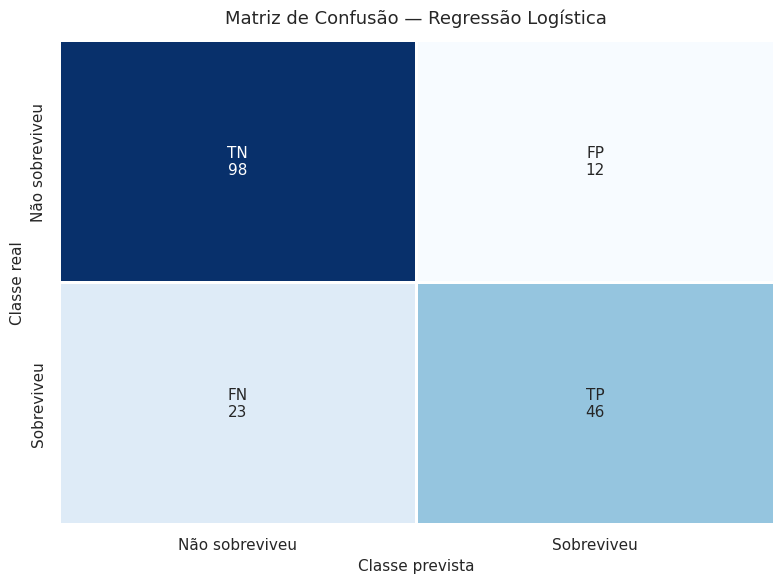

In [23]:
# Calculamos a matriz de confusão.
cm = confusion_matrix(y_test, y_pred)

# Criamos os rótulos explicativos de cada quadrante.
rotulos = np.array([
    [f"TN\n{cm[0, 0]}",
     f"FP\n{cm[0, 1]}"],

    [f"FN\n{cm[1, 0]}",
     f"TP\n{cm[1, 1]}"]
])

fig, ax = plt.subplots(figsize=(8, 6))

# Exibimos os valores da matriz.
sns.heatmap(
    cm,
    annot=rotulos,
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=2,
    linecolor="white",
    xticklabels=["Não sobreviveu", "Sobreviveu"],
    yticklabels=["Não sobreviveu", "Sobreviveu"],
    annot_kws={"fontsize": 11},
    ax=ax
)

ax.set_xlabel("Classe prevista", fontsize=11)
ax.set_ylabel("Classe real", fontsize=11)
ax.set_title("Matriz de Confusão — Regressão Logística", fontsize=13, pad=12)

plt.tight_layout()
plt.show()

In [12]:
# O classification_report reúne as principais métricas
# calculadas separadamente para cada classe.

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Não sobreviveu", "Sobreviveu"]
    )
)


                precision    recall  f1-score   support

Não sobreviveu       0.81      0.89      0.85       110
    Sobreviveu       0.79      0.67      0.72        69

      accuracy                           0.80       179
     macro avg       0.80      0.78      0.79       179
  weighted avg       0.80      0.80      0.80       179



In [13]:
# O limiar de decisão não precisa ser obrigatoriamente 0.5.
#
# Vamos observar como diferentes limiares alteram
# precisão, recall e F1-score.
#
# Um limiar menor tende a classificar mais amostras como positivas.
# Um limiar maior tende a ser mais restritivo para a classe positiva.

limiares = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

resultados_limiar = []

for t in limiares:
    previsoes = (probabilidade_classe_1 >= t).astype(int)

    resultados_limiar.append({
        "limiar": t,
        "acuracia": accuracy_score(y_test, previsoes),
        "precisao": precision_score(y_test, previsoes, zero_division=0),
        "recall": recall_score(y_test, previsoes, zero_division=0),
        "f1": f1_score(y_test, previsoes, zero_division=0)
    })

resultados_limiar = pd.DataFrame(resultados_limiar)

resultados_limiar.round(3)


,limiar,acuracia,precisao,recall,f1
0,0.3,0.760,0.655,0.797,0.719
1,0.4,0.804,0.730,0.783,0.755
2,0.5,0.804,0.793,0.667,0.724
3,0.6,0.799,0.851,0.580,0.690
4,0.7,0.788,0.897,0.507,0.648
5,0.8,0.726,0.917,0.319,0.473


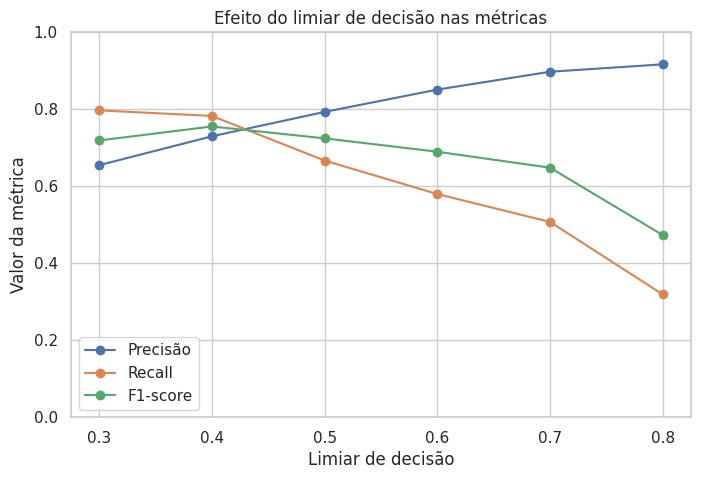

In [14]:
# Visualizamos como o limiar altera as métricas.
#
# Não existe um único limiar universalmente melhor.
# A escolha depende do tipo de erro que queremos reduzir.

plt.figure(figsize=(8, 5))

plt.plot(resultados_limiar["limiar"], resultados_limiar["precisao"], marker="o", label="Precisão")
plt.plot(resultados_limiar["limiar"], resultados_limiar["recall"], marker="o", label="Recall")
plt.plot(resultados_limiar["limiar"], resultados_limiar["f1"], marker="o", label="F1-score")

plt.xlabel("Limiar de decisão")
plt.ylabel("Valor da métrica")
plt.title("Efeito do limiar de decisão nas métricas")
plt.ylim(0, 1)
plt.legend()
plt.show()


In [18]:
# Identificamos algumas amostras em que o modelo apresentou maior
# incerteza, ou seja, probabilidades próximas de 0.5.
#
# Essas amostras são interessantes porque estão próximas da
# fronteira de decisão aprendida pelo classificador.

resultado["distancia_do_limiar"] = (
    resultado["probabilidade_classe_1"] - 0.5
).abs()

resultado.sort_values("distancia_do_limiar").head(10)


,real,probabilidade_classe_1,distancia_do_limiar
607,1,0.496128,0.003872
23,1,0.489082,0.010918
541,0,0.486477,0.013523
431,1,0.514277,0.014277
55,1,0.484257,0.015743
799,0,0.484175,0.015825
351,0,0.483996,0.016004
27,0,0.470727,0.029273
634,0,0.546047,0.046047
38,0,0.554988,0.054988


# Reflexão

Responda considerando **os resultados que você acabou de obter no seu próprio notebook**. Não responda apenas com definições dos conceitos.

1. Observe a matriz de confusão com limiar 0,5. **Qual tipo de erro aparece com maior frequência: falso positivo ou falso negativo?** O que isso revela sobre o comportamento deste modelo neste conjunto de teste?

2. Escolha **dois limiares diferentes** apresentados na tabela. Qual deles você utilizaria se o objetivo fosse **evitar que um passageiro que realmente sobreviveu fosse classificado como não sobrevivente**? Justifique utilizando os resultados que você encontrou.

3. Observe os coeficientes do modelo. **Qual atributo transformado apresentou a maior magnitude?** Por que você acha que esse atributo pode ter recebido esse peso no problema do Titanic? Sua explicação deve relacionar o atributo ao contexto do problema, e não apenas ao número apresentado pelo modelo.

4. Encontre uma amostra próxima do limiar de decisão. **Por que essa amostra é mais difícil para o modelo classificar?** Observe os atributos dessa amostra e explique sua hipótese.

5. Se você pudesse adicionar **apenas uma nova informação sobre cada passageiro** ao conjunto de dados, qual informação escolheria para tentar melhorar a classificação? Explique por que ela poderia ajudar e qual seria a dificuldade de obter essa informação antes do evento.

6. Imagine que seu modelo apresentou uma acurácia maior após uma alteração, mas o recall da classe `1` diminuiu. **Você consideraria essa alteração uma melhoria?** Responda considerando uma aplicação em que deixar de identificar um sobrevivente fosse mais grave do que gerar um falso alarme.


# 3. Prática Contextualizada

Na **Prática Contextualizada**, cada aluno deverá aplicar o conteúdo de classificação a um problema real de sua escolha.

A atividade deverá utilizar um **dataset diferente do utilizado na prática guiada** e apresentar uma aplicação coerente com um problema de classificação.

A apresentação deverá conter:

1. **Contextualização do problema** — qual problema está sendo resolvido e por que ele pode ser tratado como classificação.
2. **Dataset utilizado** — origem, quantidade de amostras, atributos e classes.
3. **Preparação dos dados** — principais decisões de pré-processamento e justificativas.
4. **Adaptação do código desenvolvido em aula** — utilização de um classificador de classificação e adequação ao novo problema.
5. **Resultados** — métricas, matriz de confusão e análise dos erros.
6. **Conclusões** — o que foi aprendido, limitações do modelo e possíveis melhorias.

A apresentação deve priorizar a **interpretação das decisões e dos resultados**, e não apenas a execução do código.

O aluno selecionado deverá apresentar sua prática **na próxima aula de laboratório**.

A avaliação seguirá os critérios definidos para a **NL2 — Prática Contextualizada**, considerando a compreensão do problema, domínio técnico, justificativa das escolhas, interpretação dos resultados e capacidade de responder às perguntas da turma.
